# H1 (RDP): Adaptive TCT vs Standard IDP under Rényi DP

Mirrors `08_h1_main.ipynb` but uses **RDP accounting throughout** (Corollary 2 / Corollary 4),
and compares **both anytime schedules** from the paper:

| Accountant | Schedule | Per-round cost | Budget unit |
|---|---|---|---|
| Standard IDP (RDP) | — | ρ = αε²/2 every round | ε_RDP |
| Adaptive TCT (RDP) | Zeta-2 (Prop 4) | K₁·ρ at registration, φ_α(t) per hit | ε_RDP |
| Adaptive TCT (RDP) | Stitched (Prop 5) | K₁·ρ at registration, φ_α(t) per hit | ε_RDP |

Non-TCT interleaved rounds charge ρ (not ε) for all accountants.

**Schedule comparison (see notebook 12):** Stitched has overhead Θ(√((1-q)k log log k)/q)
vs Zeta-2's Θ(√(k log k)/q). However, Stitched has a larger *additive* constant (8β_j/q)
that makes it *worse* for small k. Crossover near k≈150 for the paper parameters.

In [1]:
import sys
sys.path.insert(0, '..')

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from simulation.accountants.adaptive_tct import AdaptiveTCTAccountant
from simulation.accountants.standard_dp import StandardDPAccountant
from simulation.accountants.standard_tct import StandardTCTAccountant
from simulation.calibration import q_from_epsilon
from simulation.datasets import generate_synthetic_population, PopulationConfig
from simulation.query import compute_round_conversions, laplace_threshold_query

plt.rcParams.update({
    'figure.dpi': 150,
    'font.size': 13,
    'axes.labelsize': 13,
    'axes.titlesize': 14,
    'legend.fontsize': 11,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'lines.linewidth': 2.0,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

TCT_Z_COLOR = '#2166ac'    # Zeta-2 TCT
TCT_S_COLOR = '#1a9641'    # Stitched TCT
IDP_COLOR   = '#d6604d'    # Standard IDP

In [2]:
# ── Parameters ────────────────────────────────────────────────────────────────
EPSILON         = 0.01
DELTA           = 1e-2      # δ∞ for both schedules
N_USERS         = 10000
N_ROUNDS        = 1500
EPS_RDP_BUDGET  = 1.0       # per-user ε_RDP budget
TARGET_HIT_RATE = 0.02
ALPHA_POP       = 0.5
BETA_POP        = 2.0
P_PART          = 0.5
INTERLEAVE      = 0.5
SEED            = 42
N_PILOT         = 3000

# ── RDP parameters ────────────────────────────────────────────────────────────
# Choose α so that standard IDP RDP half-life ≈ 200 rounds at full participation:
#   half-life = ε_RDP / ρ = 2 / (α·ε²)  →  α = 2 / (200 · ε²) = 100
ALPHA_RDP = 75.0
rho = ALPHA_RDP * EPSILON**2 / 2.0   # ρ = αε²/2 (ε-DP → RDP conversion bound)

q = q_from_epsilon(EPSILON)
pop_cfg = PopulationConfig(
    n_users=N_USERS, alpha=ALPHA_POP, beta=BETA_POP,
    epsilon_budget=EPS_RDP_BUDGET, delta_budget=1.0,
)

print(f'ε={EPSILON},  α={ALPHA_RDP},  ρ=αε²/2={rho:.6f},  δ∞={DELTA:.0e}')
print(f'q = {q:.4f}  (NotPrior target)')
print(f'ε_RDP budget per user = {EPS_RDP_BUDGET}')
print()

# Key RDP cost landmarks for both schedules
acc_z = AdaptiveTCTAccountant(EPSILON, DELTA, alpha_rdp=ALPHA_RDP, schedule='zeta2')
acc_s = AdaptiveTCTAccountant(EPSILON, DELTA, alpha_rdp=ALPHA_RDP, schedule='stitched')

K1_z  = acc_z.compositions(1);  K1r_z = acc_z.budget_cost(K1_z)
K1_s  = acc_s.compositions(1);  K1r_s = acc_s.budget_cost(K1_s)
print(f'Zeta-2   K₁={K1_z:.1f},  K₁·ρ={K1r_z:.4f}  (registration cost)')
print(f'Stitched K₁={K1_s:.1f},  K₁·ρ={K1r_s:.4f}  (registration cost)')
print()
print('Standard DP RDP exhaustion (half-life theory):')
print(f'  Full participation:           {EPS_RDP_BUDGET/rho:.0f} rounds')
print(f'  Partial (p={P_PART}):         {EPS_RDP_BUDGET/(P_PART*rho):.0f} rounds')
print()
print('Note: Stitched schedule is worse for small k (large additive term 8β_j/q),')
print('      better for k ≳ 150 (log log k vs log k overhead). See notebook 12.')

ε=0.01,  α=75.0,  ρ=αε²/2=0.003750,  δ∞=1e-02
q = 0.4975  (NotPrior target)
ε_RDP budget per user = 1.0

Zeta-2   K₁=24.4,  K₁·ρ=0.0914  (registration cost)
Stitched K₁=84.1,  K₁·ρ=0.3152  (registration cost)

Standard DP RDP exhaustion (half-life theory):
  Full participation:           267 rounds
  Partial (p=0.5):         533 rounds

Note: Stitched schedule is worse for small k (large additive term 8β_j/q),
      better for k ≳ 150 (log log k vs log k overhead). See notebook 12.


In [3]:
# ── Calibration ───────────────────────────────────────────────────────────────
def calibrate_threshold(pop_cfg, p_participate=1.0, seed=SEED):
    rng = np.random.default_rng(seed)
    pop = generate_synthetic_population(pop_cfg, rng=np.random.default_rng(seed))
    noisy_counts = np.empty(N_PILOT)
    for i in range(N_PILOT):
        active = pop.active_users
        parts = (list(active) if p_participate >= 1.0
                 else [u for u in active if rng.random() < p_participate])
        if not parts:
            noisy_counts[i] = rng.laplace(0.0, 1.0 / EPSILON)
            continue
        cnt, _ = compute_round_conversions(parts, rng)
        noisy_counts[i] = cnt + rng.laplace(0.0, 1.0 / EPSILON)
    T = float(np.quantile(noisy_counts, 1.0 - TARGET_HIT_RATE))
    return T, float(np.mean(noisy_counts >= T))


# ── Simulation loop ───────────────────────────────────────────────────────────
def run_simulation(accountant_factory, pop_cfg, threshold,
                   p_participate=1.0, interleave_ratio=0.0, seed=SEED):
    """RDP version: non-TCT rounds charge ρ against the user's ε_RDP budget."""
    rng = np.random.default_rng(seed)
    pop = generate_synthetic_population(pop_cfg, rng=np.random.default_rng(seed))
    acc = accountant_factory()
    active_frac, avg_budget, hit_rounds = [], [], []

    for r in range(N_ROUNDS):
        active = pop.active_users
        if not active:
            break
        parts = (list(active) if p_participate >= 1.0
                 else [u for u in active if rng.random() < p_participate])
        if parts:
            is_tct = (interleave_ratio == 0.0 or rng.random() >= interleave_ratio)
            if is_tct:
                cnt, contributions = compute_round_conversions(parts, rng)
                is_top, _ = laplace_threshold_query(cnt, threshold, EPSILON, rng)
                if is_top:
                    hit_rounds.append(r)
                for i, user in enumerate(parts):
                    e, d = acc.charge(user=user, is_top=is_top,
                                      contributed=contributions[i], round_num=r)
                    user.epsilon_spent += e
                    user.delta_spent   += d
            else:
                for user in parts:
                    user.epsilon_spent += rho

        pop.drop_depleted()
        eps_dist = pop.epsilon_remaining_distribution()
        active_frac.append(pop.active_fraction)
        avg_budget.append(float(np.mean(eps_dist)) if eps_dist else 0.0)

    return active_frac, avg_budget, hit_rounds


# ── Helpers ───────────────────────────────────────────────────────────────────
def half_life(active_frac, threshold=0.5):
    for r, f in enumerate(active_frac):
        if f <= threshold:
            return r
    return len(active_frac)

def pad(curve, n, fill=None):
    fill = (curve[-1] if curve else 0.0) if fill is None else fill
    return list(curve) + [fill] * (n - len(curve))

def hl_label(hl, n):
    return f'≥{hl}' if hl >= n - 2 else str(hl)

def plot_panel(axes, z_frac, z_budget, s_frac, s_budget, idp_frac, idp_budget,
               hl_z, hl_s, hl_idp, title_left, title_right):
    """Plot retention and budget for Zeta-2 TCT, Stitched TCT, and IDP."""
    n    = max(len(z_frac), len(s_frac), len(idp_frac)) + 1
    rnds = list(range(n))
    za = pad(z_frac,   n); sa = pad(s_frac,   n); ia = pad(idp_frac,   n)
    zb = pad(z_budget, n); sb = pad(s_budget, n); ib = pad(idp_budget, n)

    ax = axes[0]
    ax.plot(rnds, ia, color=IDP_COLOR,   lw=2, linestyle=':',
            label=f'Standard (hl={hl_idp})')
    ax.plot(rnds, za, color=TCT_Z_COLOR, lw=2,
            label=f'Adaptive TCT - Zeta-2        (hl={hl_label(hl_z, n)})')
    ax.plot(rnds, sa, color=TCT_S_COLOR, lw=2, linestyle='--',
            label=f'Adaptive TCT - Stitched      (hl={hl_label(hl_s, n)})')
    ax.fill_between(rnds, ia, za, alpha=0.08, color=TCT_Z_COLOR)
    ax.axhline(0.5, color='#888', lw=0.8, linestyle=':', zorder=0)
    if hl_idp < n - 2:
        ax.axvline(hl_idp, color=IDP_COLOR, lw=0.8, linestyle=':', alpha=0.6)
    ax.set_xlabel('Query round')
    ax.set_ylabel('Fraction of users active')
    ax.set_title(title_left)
    ax.set_xlim(0, n - 1); ax.set_ylim(-0.03, 1.05)
    ax.legend(loc='upper right')

    ax = axes[1]
    ax.plot(rnds, ib, color=IDP_COLOR,   lw=2, linestyle=':', label='Standard')
    ax.plot(rnds, zb, color=TCT_Z_COLOR, lw=2,                label='Adaptive TCT - Zeta-2')
    ax.plot(rnds, sb, color=TCT_S_COLOR, lw=2, linestyle='--', label='Adaptive TCT - Stitched')
    ax.axhline(0, color='#888', lw=0.5, zorder=0)
    ax.set_xlabel('Query round')
    ax.set_ylabel(r'Mean remaining $\varepsilon_{\mathrm{RDP}}$ budget')
    ax.set_title(title_right)
    ax.set_xlim(0, n - 1); ax.set_ylim(bottom=0)
    ax.legend(loc='upper right')


print('Calibrating thresholds...')
T_full,    hr_full    = calibrate_threshold(pop_cfg, p_participate=1.0)
T_partial, hr_partial = calibrate_threshold(pop_cfg, p_participate=P_PART)
print(f'  Full:     T={T_full:.2f},  emp hit rate={hr_full:.3f}')
print(f'  Partial:  T={T_partial:.2f},  emp hit rate={hr_partial:.3f}')

Calibrating thresholds...


  Full:     T=2290.40,  emp hit rate=0.020
  Partial:  T=1295.96,  emp hit rate=0.020


## Section 1: Cost of Adaptivity under RDP

Under RDP, the per-composition cost is ρ = αε²/2 instead of ε. The K-schedule is unchanged.
Registration cost K₁·ρ << K₁·ε — the RDP advantage compounds with the TCT advantage.

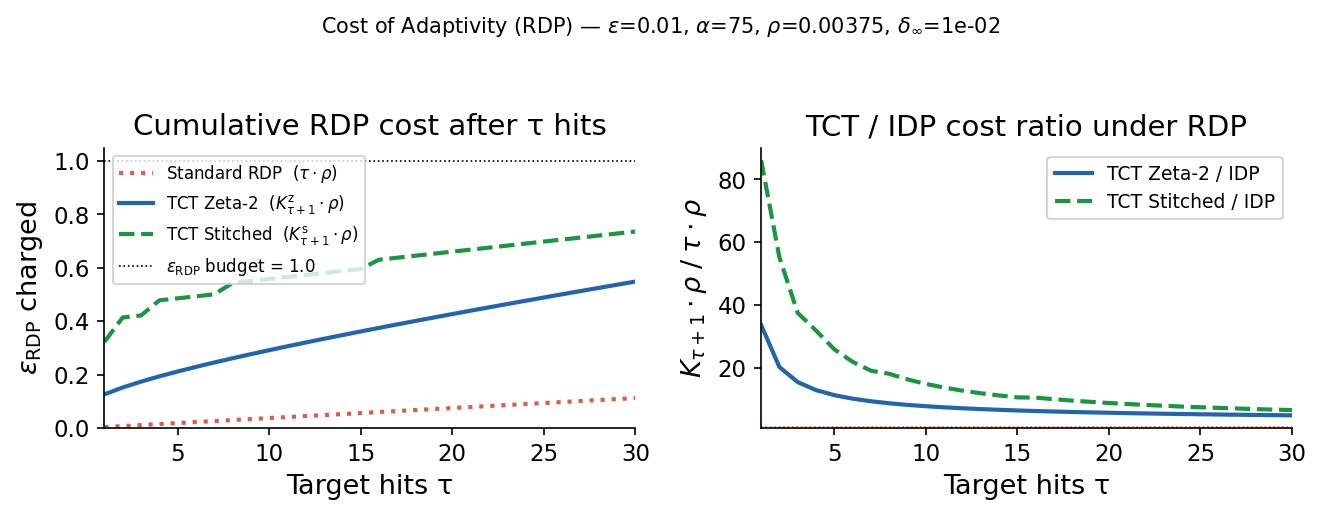

   τ     IDP τ·ρ      Zeta-2    Stitched   ratio-z   ratio-s
------------------------------------------------------------
   1      0.0038      0.1262      0.3228    33.647x    86.076x
   5      0.0188      0.2117      0.4854    11.293x    25.890x
  10      0.0375      0.2915      0.5578     7.772x    14.875x
  20      0.0750      0.4266      0.6601     5.688x     8.801x
  30      0.1125      0.5482      0.7355     4.873x     6.538x


In [4]:
tau_range  = list(range(1, 31))
cost_idp   = [t * rho for t in tau_range]
cost_zeta2 = [acc_z.budget_cost(acc_z.compositions(t + 1)) for t in tau_range]
cost_stitch = [acc_s.budget_cost(acc_s.compositions(t + 1)) for t in tau_range]

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))

ax = axes[0]
ax.plot(tau_range, cost_idp,    color=IDP_COLOR,   lw=2, linestyle=':',
        label=r'Standard RDP  ($\tau\cdot\rho$)')
ax.plot(tau_range, cost_zeta2,  color=TCT_Z_COLOR, lw=2,
        label=r'TCT Zeta-2  ($K^{\mathrm{z}}_{\tau+1}\cdot\rho$)')
ax.plot(tau_range, cost_stitch, color=TCT_S_COLOR, lw=2, linestyle='--',
        label=r'TCT Stitched  ($K^{\mathrm{s}}_{\tau+1}\cdot\rho$)')
ax.axhline(EPS_RDP_BUDGET, color='black', lw=0.8, linestyle=':',
           label=rf'$\varepsilon_{{\mathrm{{RDP}}}}$ budget = {EPS_RDP_BUDGET}')
ax.set_xlabel('Target hits τ')
ax.set_ylabel(r'$\varepsilon_{\mathrm{RDP}}$ charged')
ax.set_title('Cumulative RDP cost after τ hits')
ax.set_xlim(1, 30); ax.set_ylim(bottom=0)
ax.legend(loc='upper left', fontsize=8)

ax = axes[1]
ratio_z = [z / i for z, i in zip(cost_zeta2,  cost_idp)]
ratio_s = [s / i for s, i in zip(cost_stitch, cost_idp)]
ax.plot(tau_range, ratio_z, color=TCT_Z_COLOR, lw=2, label='TCT Zeta-2 / IDP')
ax.plot(tau_range, ratio_s, color=TCT_S_COLOR, lw=2, linestyle='--', label='TCT Stitched / IDP')
ax.axhline(1.0, color=IDP_COLOR, lw=0.8, linestyle=':')
ax.set_xlabel('Target hits τ')
ax.set_ylabel(r'$K_{\tau+1}\cdot\rho \;/\; \tau\cdot\rho$')
ax.set_title('TCT / IDP cost ratio under RDP')
ax.set_xlim(1, 30); ax.legend(fontsize=9)

fig.suptitle(
    rf'Cost of Adaptivity (RDP) — $\varepsilon$={EPSILON}, $\alpha$={ALPHA_RDP:.0f}, '
    rf'$\rho$={rho:.5f}, $\delta_\infty$={DELTA:.0e}',
    fontsize=10,
)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('../figures/h1_rdp_cost_of_adaptivity.png', bbox_inches='tight', dpi=200)
plt.show()

print(f'{"τ":>4}  {"IDP τ·ρ":>10}  {"Zeta-2":>10}  {"Stitched":>10}  {"ratio-z":>8}  {"ratio-s":>8}')
print('-' * 60)
for t in [1, 5, 10, 20, 30]:
    print(f'{t:>4}  {cost_idp[t-1]:>10.4f}  {cost_zeta2[t-1]:>10.4f}  {cost_stitch[t-1]:>10.4f}'
          f'  {ratio_z[t-1]:>8.3f}x  {ratio_s[t-1]:>8.3f}x')

## Section 2: Full Participation, No Interleaving (S1)

Standard IDP RDP exhausts at ε_RDP / ρ = **200 rounds**.  
Both TCT schedules charge only at registration + hits. Stitched has a larger K₁·ρ
(bigger upfront cost) but lower per-hit increments for users with many hits.

S1: full participation, no interleaving...


Zeta-2 hl=1500  Stitched hl=1500  IDP hl=266


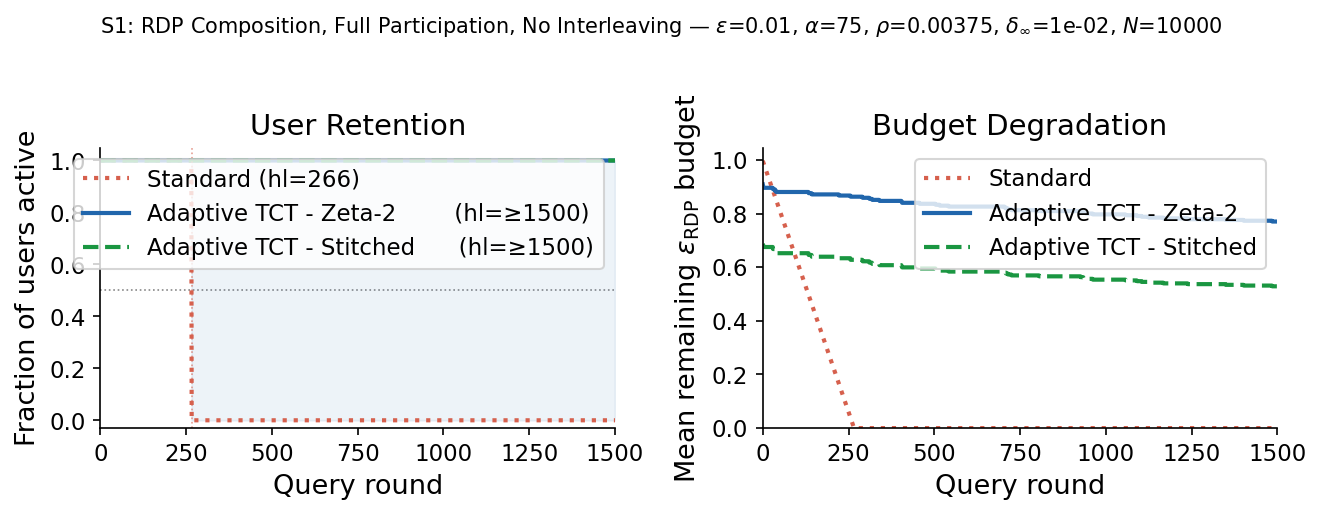

In [5]:
print('S1: full participation, no interleaving...')
tct1z_frac, tct1z_budget, _ = run_simulation(
    lambda: AdaptiveTCTAccountant(EPSILON, DELTA, alpha_rdp=ALPHA_RDP,
                                  schedule='zeta2', independent=True),
    pop_cfg, T_full, p_participate=1.0, interleave_ratio=0.0)
tct1s_frac, tct1s_budget, _ = run_simulation(
    lambda: AdaptiveTCTAccountant(EPSILON, DELTA, alpha_rdp=ALPHA_RDP,
                                  schedule='stitched', independent=True),
    pop_cfg, T_full, p_participate=1.0, interleave_ratio=0.0)
idp1_frac, idp1_budget, _ = run_simulation(
    lambda: StandardDPAccountant(rho),
    pop_cfg, T_full, p_participate=1.0, interleave_ratio=0.0)

hl_tct1z = half_life(tct1z_frac); hl_tct1s = half_life(tct1s_frac); hl_idp1 = half_life(idp1_frac)
print(f'Zeta-2 hl={hl_tct1z}  Stitched hl={hl_tct1s}  IDP hl={hl_idp1}')

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
plot_panel(axes, tct1z_frac, tct1z_budget, tct1s_frac, tct1s_budget, idp1_frac, idp1_budget,
           hl_tct1z, hl_tct1s, hl_idp1, 'User Retention', 'Budget Degradation')
fig.suptitle(
    rf'S1: RDP Composition, Full Participation, No Interleaving — '
    rf'$\varepsilon$={EPSILON}, $\alpha$={ALPHA_RDP:.0f}, $\rho$={rho:.5f}, $\delta_\infty$={DELTA:.0e}, $N$={N_USERS}',
    fontsize=10,
)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('../figures/h1_rdp_s1.png', bbox_inches='tight', dpi=200)
plt.show()

## Section 3: Full Participation, 50% Interleaving (S2)

50% of rounds are non-TCT, each charging ρ to all participants.
Standard IDP is unaffected; both TCT schedules accumulate extra ρ charges on non-TCT rounds.

S2: full participation, 50% interleaving...


Zeta-2 hl=459  Stitched hl=345  IDP hl=266


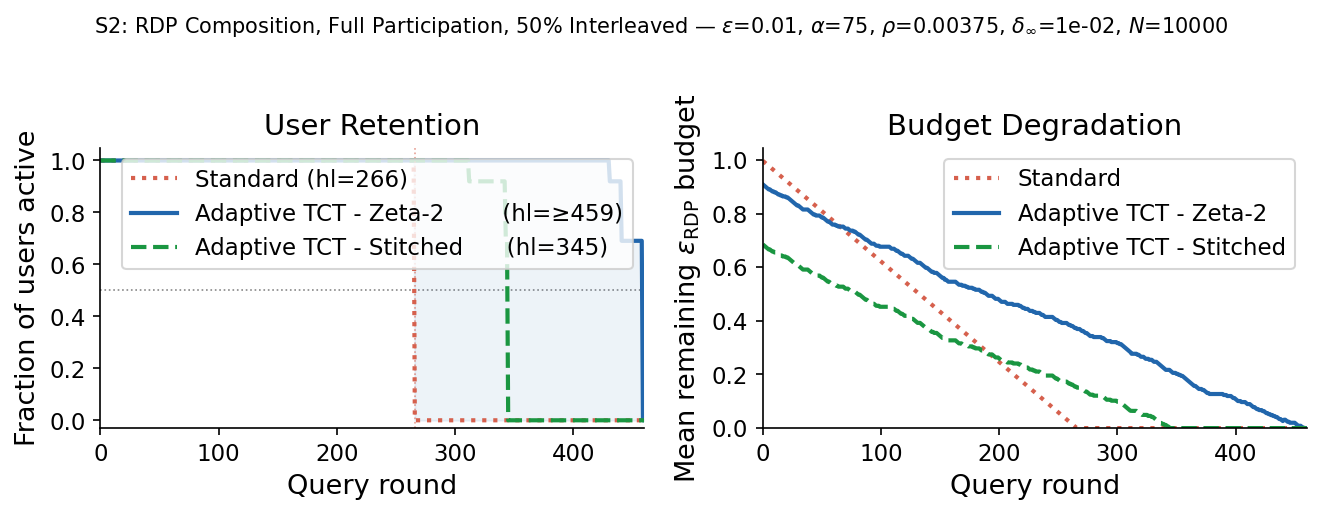

In [6]:
print('S2: full participation, 50% interleaving...')
tct2z_frac, tct2z_budget, _ = run_simulation(
    lambda: AdaptiveTCTAccountant(EPSILON, DELTA, alpha_rdp=ALPHA_RDP,
                                  schedule='zeta2', independent=True),
    pop_cfg, T_full, p_participate=1.0, interleave_ratio=INTERLEAVE)
tct2s_frac, tct2s_budget, _ = run_simulation(
    lambda: AdaptiveTCTAccountant(EPSILON, DELTA, alpha_rdp=ALPHA_RDP,
                                  schedule='stitched', independent=True),
    pop_cfg, T_full, p_participate=1.0, interleave_ratio=INTERLEAVE)
idp2_frac, idp2_budget, _ = run_simulation(
    lambda: StandardDPAccountant(rho),
    pop_cfg, T_full, p_participate=1.0, interleave_ratio=INTERLEAVE)

hl_tct2z = half_life(tct2z_frac); hl_tct2s = half_life(tct2s_frac); hl_idp2 = half_life(idp2_frac)
print(f'Zeta-2 hl={hl_tct2z}  Stitched hl={hl_tct2s}  IDP hl={hl_idp2}')

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
plot_panel(axes, tct2z_frac, tct2z_budget, tct2s_frac, tct2s_budget, idp2_frac, idp2_budget,
           hl_tct2z, hl_tct2s, hl_idp2, 'User Retention', 'Budget Degradation')
fig.suptitle(
    rf'S2: RDP Composition, Full Participation, 50% Interleaved — '
    rf'$\varepsilon$={EPSILON}, $\alpha$={ALPHA_RDP:.0f}, $\rho$={rho:.5f}, $\delta_\infty$={DELTA:.0e}, $N$={N_USERS}',
    fontsize=10,
)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('../figures/h1_rdp_s2.png', bbox_inches='tight', dpi=200)
plt.show()

## Section 4: Partial Participation (50%), 50% Interleaving (S3)

Most realistic scenario. Standard IDP exhausts at ε_RDP / (p·ρ) = **400 rounds** (p=0.5).
With partial participation, each user accumulates fewer hits — this is where the stitched
schedule's larger K₁ registration cost matters most.

S3: 50% participation, 50% interleaving...


Zeta-2 hl=991  Stitched hl=773  IDP hl=532  adv-z=+459 (86%)  adv-s=+241 (45%)


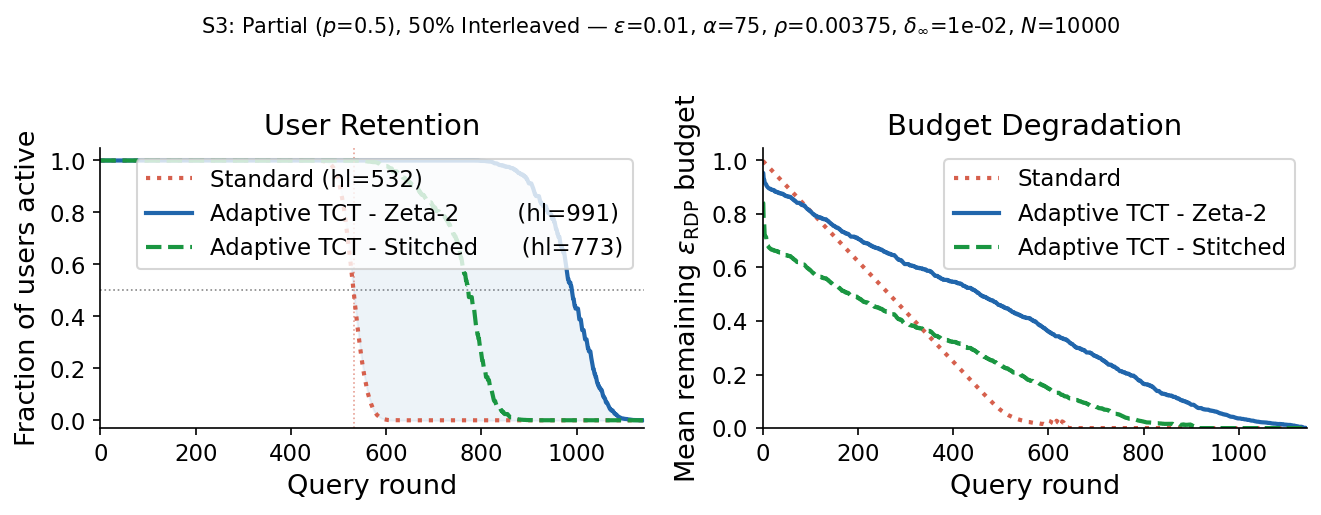

In [7]:
print('S3: 50% participation, 50% interleaving...')
tct3z_frac, tct3z_budget, _ = run_simulation(
    lambda: AdaptiveTCTAccountant(EPSILON, DELTA, alpha_rdp=ALPHA_RDP,
                                  schedule='zeta2', independent=True),
    pop_cfg, T_partial, p_participate=P_PART, interleave_ratio=INTERLEAVE)
tct3s_frac, tct3s_budget, _ = run_simulation(
    lambda: AdaptiveTCTAccountant(EPSILON, DELTA, alpha_rdp=ALPHA_RDP,
                                  schedule='stitched', independent=True),
    pop_cfg, T_partial, p_participate=P_PART, interleave_ratio=INTERLEAVE)
idp3_frac, idp3_budget, _ = run_simulation(
    lambda: StandardDPAccountant(rho),
    pop_cfg, T_partial, p_participate=P_PART, interleave_ratio=INTERLEAVE)

hl_tct3z = half_life(tct3z_frac); hl_tct3s = half_life(tct3s_frac); hl_idp3 = half_life(idp3_frac)
print(f'Zeta-2 hl={hl_tct3z}  Stitched hl={hl_tct3s}  IDP hl={hl_idp3}  '
      f'adv-z=+{hl_tct3z-hl_idp3} ({100*(hl_tct3z-hl_idp3)/max(hl_idp3,1):.0f}%)  '
      f'adv-s=+{hl_tct3s-hl_idp3} ({100*(hl_tct3s-hl_idp3)/max(hl_idp3,1):.0f}%)')

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
plot_panel(axes, tct3z_frac, tct3z_budget, tct3s_frac, tct3s_budget, idp3_frac, idp3_budget,
           hl_tct3z, hl_tct3s, hl_idp3, 'User Retention', 'Budget Degradation')
fig.suptitle(
    rf'S3: Partial ($p$={P_PART}), 50% Interleaved — '
    rf'$\varepsilon$={EPSILON}, $\alpha$={ALPHA_RDP:.0f}, $\rho$={rho:.5f}, $\delta_\infty$={DELTA:.0e}, $N$={N_USERS}',
    fontsize=10,
)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('../figures/h1_rdp_s3.png', bbox_inches='tight', dpi=200)
plt.show()

## Section 5: Paper Figure — Combined H1 RDP Retention

Three-scenario comparison (S1, S2, S3) for the paper.

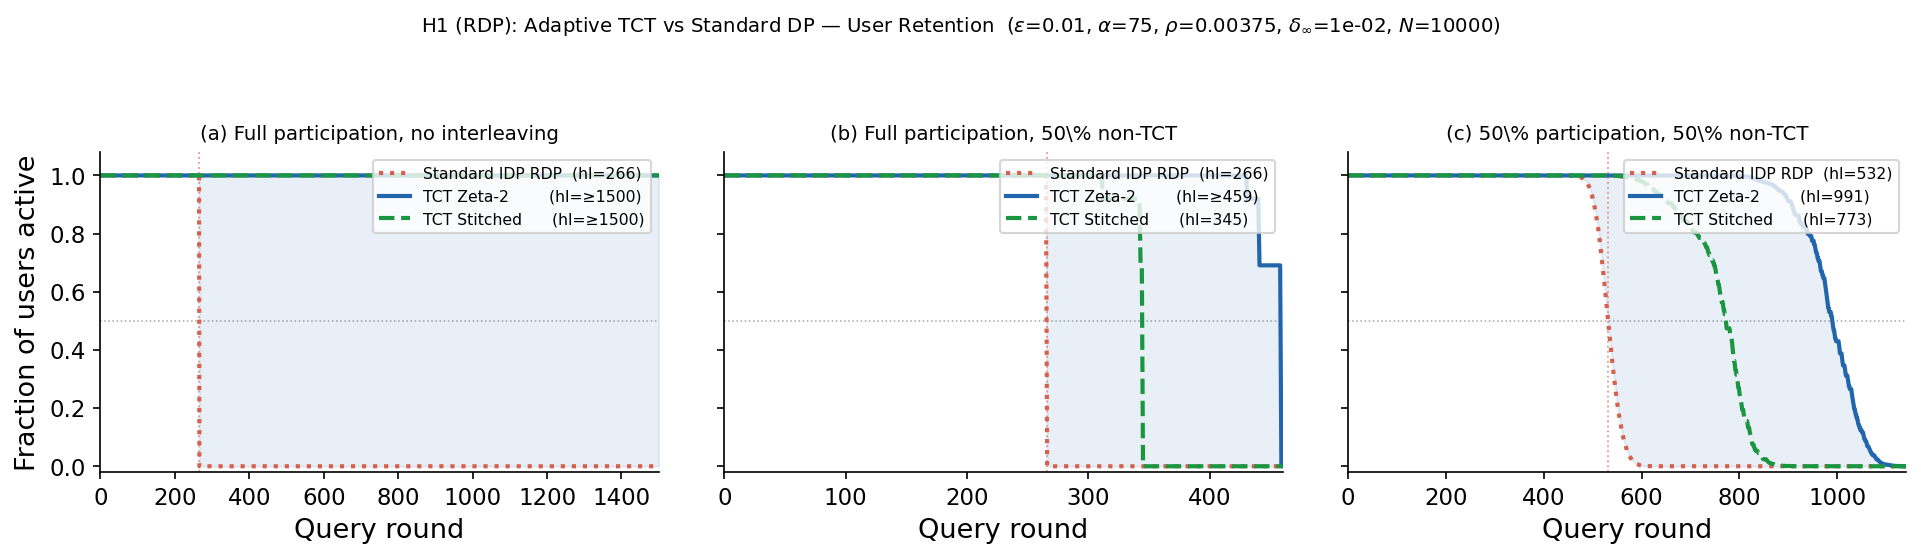

Saved figures/paper_fig_h1_rdp.png


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)

panels = [
    (axes[0], tct1z_frac, tct1s_frac, idp1_frac, hl_tct1z, hl_tct1s, hl_idp1,
     r'(a) Full participation, no interleaving'),
    (axes[1], tct2z_frac, tct2s_frac, idp2_frac, hl_tct2z, hl_tct2s, hl_idp2,
     rf'(b) Full participation, {int(INTERLEAVE*100)}\% non-TCT'),
    (axes[2], tct3z_frac, tct3s_frac, idp3_frac, hl_tct3z, hl_tct3s, hl_idp3,
     rf'(c) {int(P_PART*100)}\% participation, {int(INTERLEAVE*100)}\% non-TCT'),
]

for i, (ax, zf, sf, idpf, hl_z, hl_s, hl_i, panel) in enumerate(panels):
    n    = max(len(zf), len(sf), len(idpf)) + 1
    rnds = list(range(n))
    za = pad(zf,   n); sa = pad(sf,   n); ia = pad(idpf, n)

    ax.plot(rnds, ia, color=IDP_COLOR,   lw=2.0, linestyle=':',
            label=f'Standard IDP RDP  (hl={hl_i})')
    ax.plot(rnds, za, color=TCT_Z_COLOR, lw=2.0,
            label=f'TCT Zeta-2        (hl={hl_label(hl_z, n)})')
    ax.plot(rnds, sa, color=TCT_S_COLOR, lw=2.0, linestyle='--',
            label=f'TCT Stitched      (hl={hl_label(hl_s, n)})')
    ax.fill_between(rnds, ia, za, alpha=0.10, color=TCT_Z_COLOR)
    ax.axhline(0.5, color='#aaa', lw=0.75, linestyle=':', zorder=0)
    if hl_i < n - 2:
        ax.axvline(hl_i, color=IDP_COLOR, lw=0.9, linestyle=':', alpha=0.6)
    ax.set_xlabel('Query round')
    ax.set_title(panel, fontsize=9.5)
    ax.set_xlim(0, n - 1); ax.set_ylim(-0.02, 1.08)
    ax.legend(loc='upper right', fontsize=7.5)

axes[0].set_ylabel('Fraction of users active')

fig.suptitle(
    rf'H1 (RDP): Adaptive TCT vs Standard DP — User Retention'
    rf'  ($\varepsilon$={EPSILON}, $\alpha$={ALPHA_RDP:.0f}, $\rho$={rho:.5f},'
    rf' $\delta_\infty$={DELTA:.0e}, $N$={N_USERS})',
    fontsize=9.5,
)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig('../figures/paper_fig_h1_rdp.png', bbox_inches='tight', dpi=200)
plt.show()
print('Saved figures/paper_fig_h1_rdp.png')


## Section 6: Summary

In [9]:
rows = [
    {'Scenario': 'S1: Full, no interleave',     'p': 1.0,    'intlv': 0.0,
     'Z_hl': hl_tct1z, 'S_hl': hl_tct1s, 'IDP_hl': hl_idp1},
    {'Scenario': 'S2: Full, interleave 50%',     'p': 1.0,    'intlv': INTERLEAVE,
     'Z_hl': hl_tct2z, 'S_hl': hl_tct2s, 'IDP_hl': hl_idp2},
    {'Scenario': 'S3: Partial 50%, intlv 50%',   'p': P_PART, 'intlv': INTERLEAVE,
     'Z_hl': hl_tct3z, 'S_hl': hl_tct3s, 'IDP_hl': hl_idp3},
]
df = pd.DataFrame(rows)
df['Adv-Z'] = df['Z_hl'] - df['IDP_hl']
df['Adv-S'] = df['S_hl'] - df['IDP_hl']
df['Adv-Z%'] = (100 * df['Adv-Z'] / df['IDP_hl'].clip(lower=1)).round(0).astype(int).astype(str) + '%'
df['Adv-S%'] = (100 * df['Adv-S'] / df['IDP_hl'].clip(lower=1)).round(0).astype(int).astype(str) + '%'
print(df[['Scenario', 'p', 'intlv', 'Z_hl', 'S_hl', 'IDP_hl', 'Adv-Z', 'Adv-Z%', 'Adv-S', 'Adv-S%']].to_string(index=False))
print()
print(f'α={ALPHA_RDP:.0f}, ρ={rho:.5f}, ε_RDP budget={EPS_RDP_BUDGET}')
print(f'(ε-DP equivalent: ε={EPSILON}, IDP S1 half-life would be {int(1.0/EPSILON)} rounds)')
print()
print('Note: Stitched schedule has larger K₁·ρ registration cost, so it can be worse')
print(f'      for low-hit-count users. Crossover vs Zeta-2 occurs near k≈150 hits.')

                  Scenario   p  intlv  Z_hl  S_hl  IDP_hl  Adv-Z Adv-Z%  Adv-S Adv-S%
   S1: Full, no interleave 1.0    0.0  1500  1500     266   1234   464%   1234   464%
  S2: Full, interleave 50% 1.0    0.5   459   345     266    193    73%     79    30%
S3: Partial 50%, intlv 50% 0.5    0.5   991   773     532    459    86%    241    45%

α=75, ρ=0.00375, ε_RDP budget=1.0
(ε-DP equivalent: ε=0.01, IDP S1 half-life would be 100 rounds)

Note: Stitched schedule has larger K₁·ρ registration cost, so it can be worse
      for low-hit-count users. Crossover vs Zeta-2 occurs near k≈150 hits.


## Section 7: Paper Figures — S1 / S2 / S3 Side-by-Side

Three-panel figures for the NeurIPS paper: S1 (no interleaving), S2 (50% non-TCT,
full participation), S3 (50% participation, 50% non-TCT — most realistic scenario).


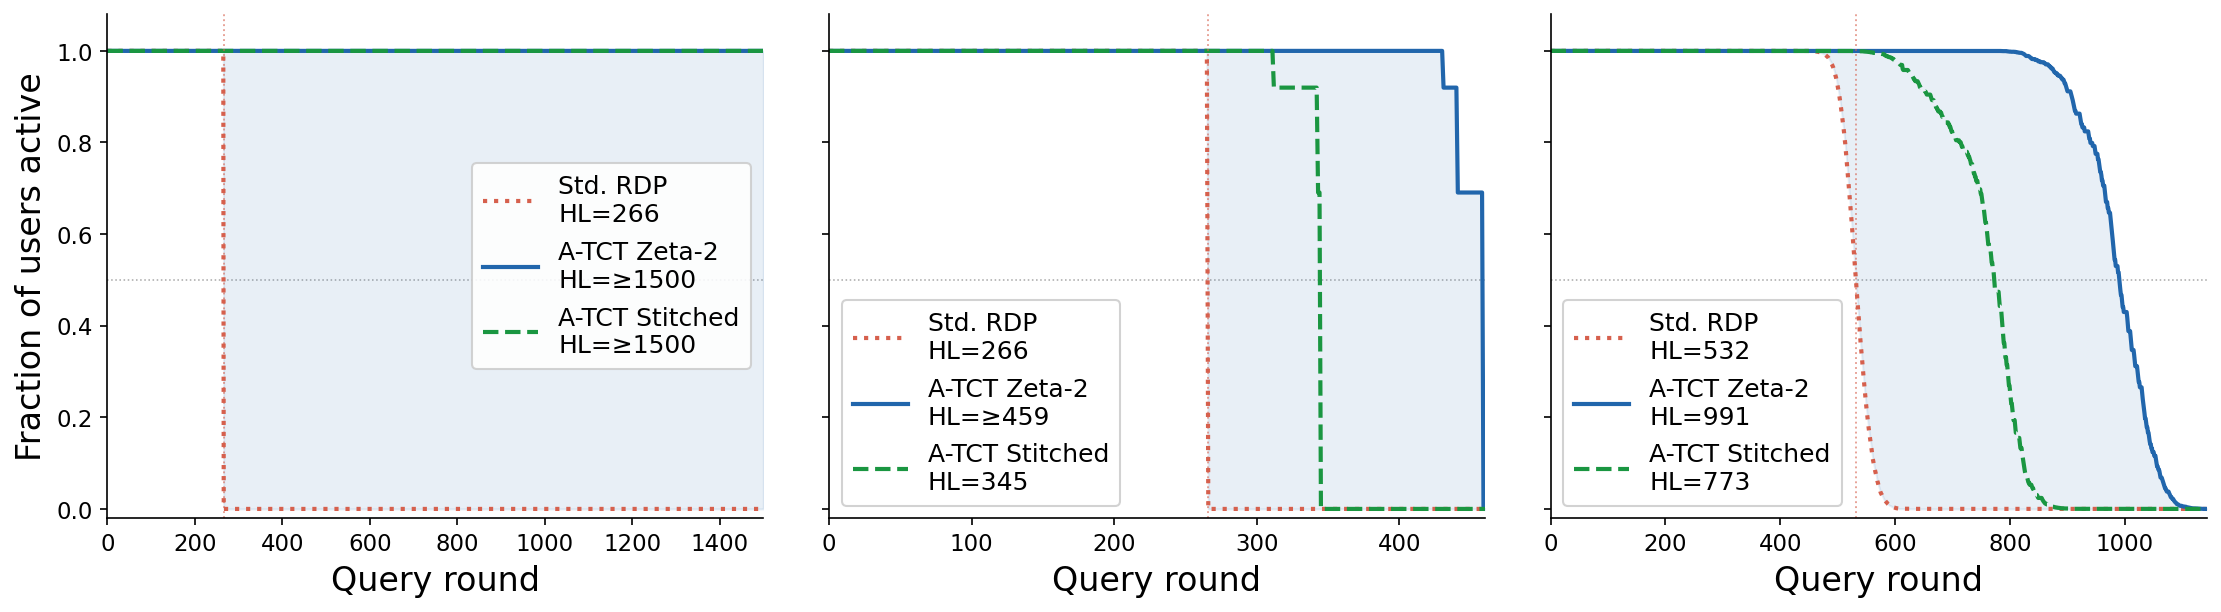

Saved figures/h1_rdp_s1_s2_s3_retention.png


In [80]:
# ── Combined S1 / S2 / S3: User Retention ───────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)

panel_data = [
    (axes[0], tct1z_frac, tct1s_frac, idp1_frac, hl_tct1z, hl_tct1s, hl_idp1,
     r'(a) S1: Full participation, all TCT', 'center right'),
    (axes[1], tct2z_frac, tct2s_frac, idp2_frac, hl_tct2z, hl_tct2s, hl_idp2,
     rf'(b) S2: Full participation, {int(INTERLEAVE*100)}% non-TCT rounds', 'lower left'),
    (axes[2], tct3z_frac, tct3s_frac, idp3_frac, hl_tct3z, hl_tct3s, hl_idp3,
     rf'(c) S3: {int(P_PART*100)}% participation, {int(INTERLEAVE*100)}% non-TCT', 'lower left'),
]

for ax, zf, sf, idpf, hl_z, hl_s, hl_i, panel_title, leg_loc in panel_data:
    n    = max(len(zf), len(sf), len(idpf)) + 1
    rnds = list(range(n))
    za = pad(zf,   n); sa = pad(sf,   n); ia = pad(idpf, n)

    ax.plot(rnds, ia, color=IDP_COLOR,   lw=2.0, linestyle=':',
            label=f'Std. RDP\nHL={hl_i}')
    ax.plot(rnds, za, color=TCT_Z_COLOR, lw=2.0,
            label=f'A-TCT Zeta-2\nHL={hl_label(hl_z, n)}')
    ax.plot(rnds, sa, color=TCT_S_COLOR, lw=2.0, linestyle='--',
            label=f'A-TCT Stitched\nHL={hl_label(hl_s, n)}')
    ax.fill_between(rnds, ia, za, alpha=0.10, color=TCT_Z_COLOR)
    ax.axhline(0.5, color='#aaa', lw=0.75, linestyle=':', zorder=0)
    if hl_i < n - 2:
        ax.axvline(hl_i, color=IDP_COLOR, lw=0.9, linestyle=':', alpha=0.6)
    ax.set_xlabel('Query round', fontsize=16)
    # ax.set_title(panel_title, fontsize=15)
    ax.set_xlim(0, n - 1); ax.set_ylim(-0.02, 1.08)
    ax.legend(
        loc=leg_loc,
        fontsize=12,
        frameon=True,
        framealpha=0.88,
        borderpad=0.45,
        labelspacing=0.55,
        handlelength=2.2
    )

axes[0].set_ylabel('Fraction of users active', fontsize=16)

plt.tight_layout()
fig.subplots_adjust(top=0.85)
plt.savefig('../figures/h1_rdp_s1_s2_s3_retention.png', bbox_inches='tight', dpi=200)
plt.show()
print('Saved figures/h1_rdp_s1_s2_s3_retention.png')


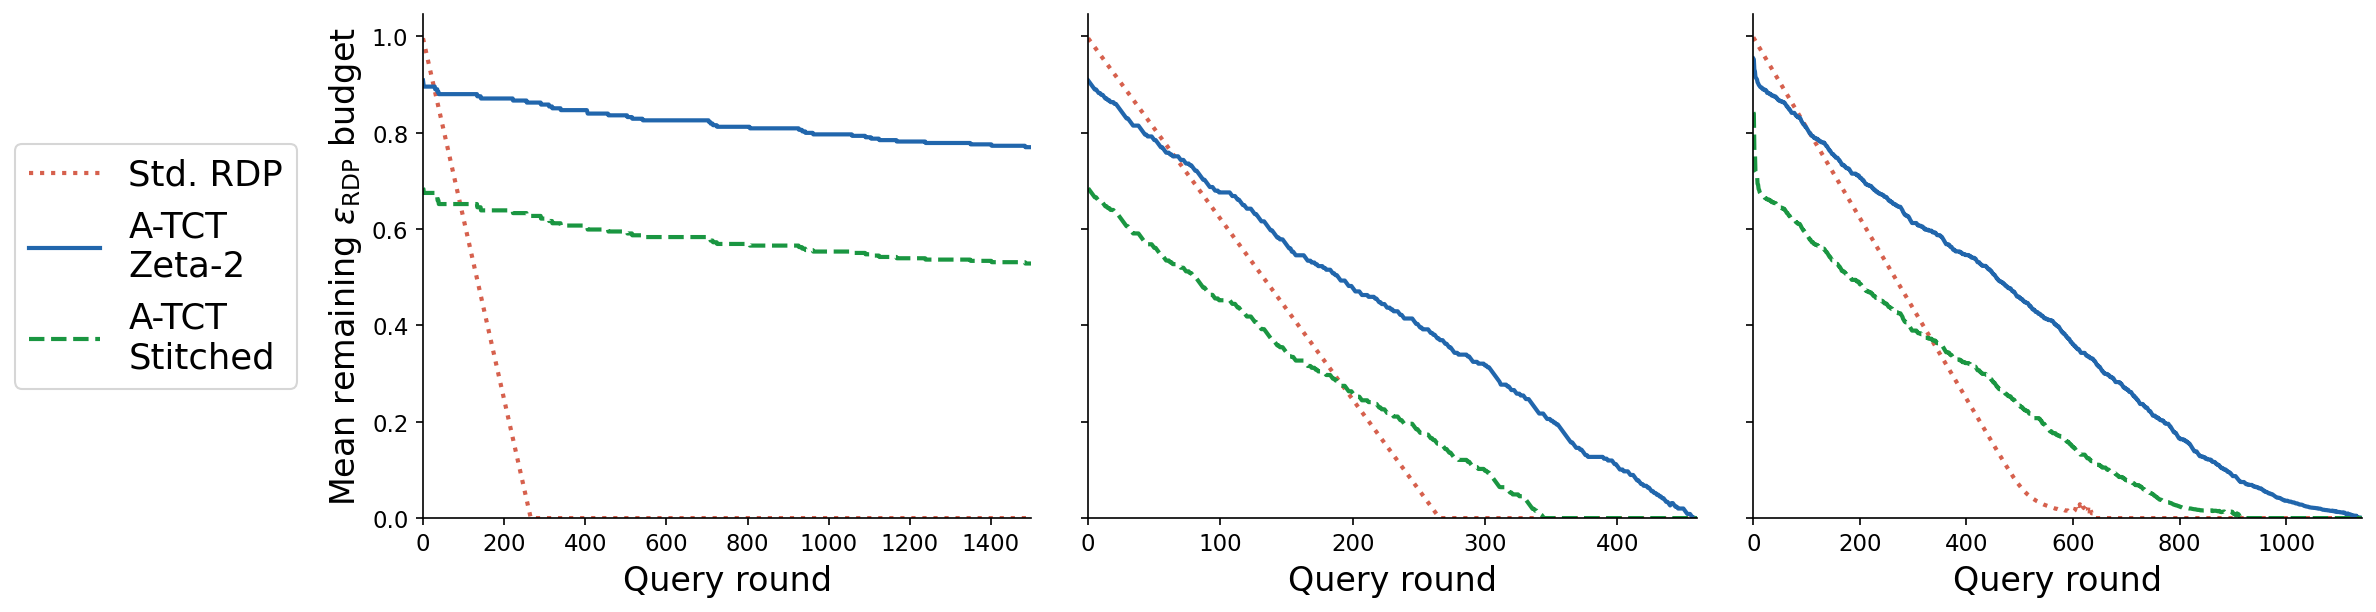

Saved figures/h1_rdp_s1_s2_s3_budget.png


In [81]:
# ── Combined S1 / S2 / S3: Budget Degradation ───────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)

panel_data = [
    (axes[0], tct1z_budget, tct1s_budget, idp1_budget,
     r'(a) S1: Full participation, all TCT'),
    (axes[1], tct2z_budget, tct2s_budget, idp2_budget,
     rf'(b) S2: Full participation, {int(INTERLEAVE*100)}% non-TCT'),
    (axes[2], tct3z_budget, tct3s_budget, idp3_budget,
     rf'(c) S3: {int(P_PART*100)}% participation, {int(INTERLEAVE*100)}% non-TCT'),
]

for ax, zb, sb, ib, panel_title in panel_data:
    n    = max(len(zb), len(sb), len(ib)) + 1
    rnds = list(range(n))
    zb_ = pad(zb, n); sb_ = pad(sb, n); ib_ = pad(ib, n)

    ax.plot(rnds, ib_, color=IDP_COLOR,   lw=2.0, linestyle=':', label='Std. RDP')
    ax.plot(rnds, zb_, color=TCT_Z_COLOR, lw=2.0,               label='A-TCT\nZeta-2')
    ax.plot(rnds, sb_, color=TCT_S_COLOR, lw=2.0, linestyle='--', label='A-TCT\nStitched')
    ax.axhline(0, color='#888', lw=0.5, zorder=0)
    ax.set_xlabel('Query round',fontsize=16)
   # ax.set_title(panel_title, fontsize=15.5)
    ax.set_xlim(0, n - 1); ax.set_ylim(bottom=0)

axes[0].set_ylabel(r'Mean remaining $\varepsilon_{\mathrm{RDP}}$ budget', fontsize=16)

# Single shared legend to the left of all panels
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels,
           loc='center left',
           bbox_to_anchor=(0.01, 0.50),
           borderaxespad=0,
           frameon=True, fontsize=17)

plt.tight_layout()
fig.subplots_adjust(left=0.18, top=0.85)
plt.savefig('../figures/h1_rdp_s1_s2_s3_budget.png', bbox_inches='tight', dpi=200)
plt.show()
print('Saved figures/h1_rdp_s1_s2_s3_budget.png')


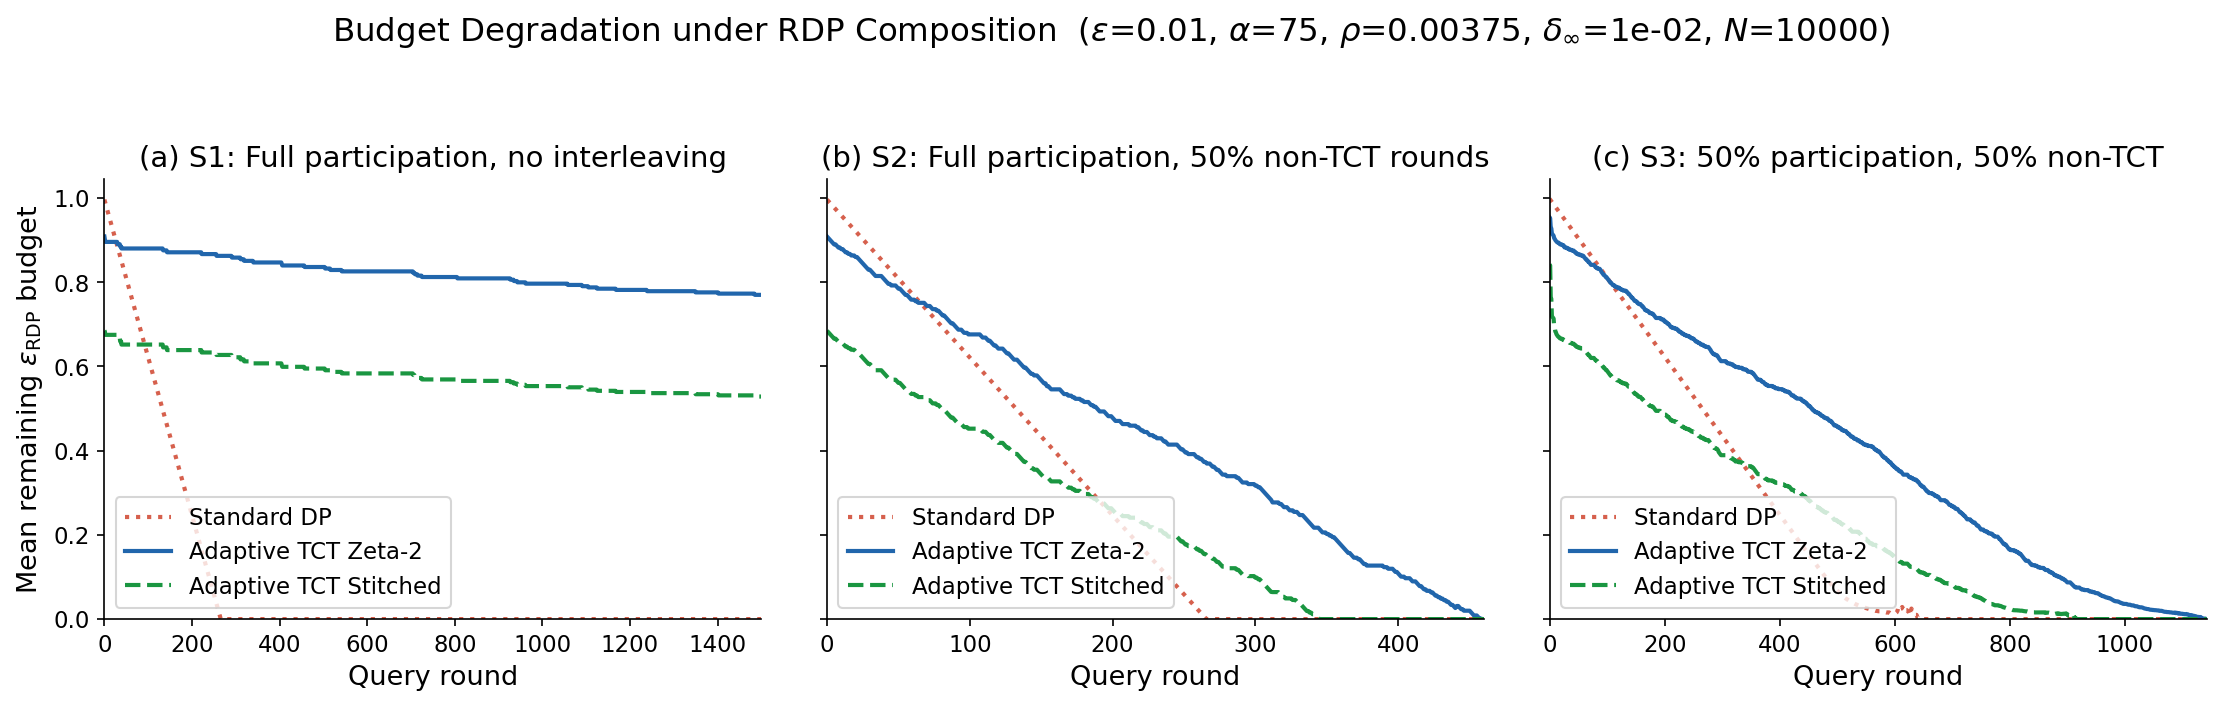

Saved figures/h1_rdp_s1_s2_s3_budget.png


In [58]:
# ── Combined S1 / S2 / S3: Budget Degradation ───────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)

panel_data = [
    (axes[0], tct1z_budget, tct1s_budget, idp1_budget,
     r'(a) S1: Full participation, no interleaving'),
    (axes[1], tct2z_budget, tct2s_budget, idp2_budget,
     rf'(b) S2: Full participation, {int(INTERLEAVE*100)}% non-TCT rounds'),
    (axes[2], tct3z_budget, tct3s_budget, idp3_budget,
     rf'(c) S3: {int(P_PART*100)}% participation, {int(INTERLEAVE*100)}% non-TCT'),
]

for ax, zb, sb, ib, panel_title in panel_data:
    n    = max(len(zb), len(sb), len(ib)) + 1
    rnds = list(range(n))
    zb_ = pad(zb, n); sb_ = pad(sb, n); ib_ = pad(ib, n)

    ax.plot(rnds, ib_, color=IDP_COLOR,   lw=2.0, linestyle=':', label='Standard DP')
    ax.plot(rnds, zb_, color=TCT_Z_COLOR, lw=2.0,               label='Adaptive TCT Zeta-2')
    ax.plot(rnds, sb_, color=TCT_S_COLOR, lw=2.0, linestyle='--', label='Adaptive TCT Stitched')
    ax.axhline(0, color='#888', lw=0.5, zorder=0)
    ax.set_xlabel('Query round')
    ax.set_title(panel_title)
    ax.set_xlim(0, n - 1); ax.set_ylim(bottom=0)
    ax.legend(loc='lower left')

axes[0].set_ylabel(r'Mean remaining $\varepsilon_{\mathrm{RDP}}$ budget')

fig.suptitle(
    rf'Budget Degradation under RDP Composition'
    rf'  ($\varepsilon$={EPSILON}, $\alpha$={ALPHA_RDP:.0f}, $\rho$={rho:.5f},'
    rf' $\delta_\infty$={DELTA:.0e}, $N$={N_USERS})',
)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig('../figures/h1_rdp_s1_s2_s3_budget.png', bbox_inches='tight', dpi=200)
plt.show()
print('Saved figures/h1_rdp_s1_s2_s3_budget.png')
